# **CSI 4142: Assignment 3** </br> Predictive analysis

## **Group members**
**Group 75**

| Name | Student ID |
|------|------------|
| Zixin Fan | 300296371 |
| Solin Maaroof | 300250903 | 

## **Task distribution**
- Zixin Fan: Regression - data cleaning, exploratory data analysis (EDA), outlier detection, linear regression modeling, feature engineering, and result analysis.

- Solin Maaroof: Classification - data preprocessing, decision tree modeling, model evaluation, and result analysis.

## **Libraries and Packages**

In [1]:
import pandas as pd # For data manipulation and analysis using DataFrames
import numpy as np # For numberical computing and array/ matrix operations
import seaborn as sns # For statistical data visualization with better styling
import matplotlib.pyplot as plt # For creating basic plots and visualizations
from sklearn.neighbors import LocalOutlierFactor # import lof model for outlier detection
from sklearn.model_selection import train_test_split # train / validation / test split
from sklearn.linear_model import LinearRegression  # linear regression model
from sklearn.model_selection import cross_val_score # for performing cross-validation and evaluating model performance
from sklearn.metrics import mean_squared_error,r2_score # evaluation metrics
from sklearn.model_selection import KFold # for manually splitting data into k folds for cross-validation
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold

## **Dataset 1**: Medical Cost Personal

### Description
- **Dataset Name:** Medical Cost Personal Dataset
- **Owner:** Miri Choi (Kaggle)
- **Purpose:** This dataset contains demographic and health-related information of individuals along with their medical insurance charges.
- **Shape:** This dataset contains 1338 rows and 7 columns, as shown by dataset.shape.
- **Features:**
  - Age (Numerical): Age of the primary beneficiary.
  - Sex (Categorical): Gender of the insurance beneficiary (male or female).
  - BMI (Numerical): Body mass index, a measure of body weight relative to height.
  - Children (Numerical): Number of dependents covered by health insurance.
  - Smoker (Categorical): Indicates whether the beneficiary is a smoker (yes or no).
  - Region (Categorical): Residential region in the United States (northeast, southeast, southwest, northwest).
  - Charges (Numerical): Individual medical costs billed by health insurance.


## Regression Empirical Study with Linear Regression

In [2]:
dataset1=pd.read_csv( "https://raw.githubusercontent.com/Zixin-Fan/CSI4142-A3/main/insurance.csv") # Read 'insurance.csv' from github
dataset1.head() # show the first 5 rows of the dataset

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
dataset1.shape

(1338, 7)

### a) Data Cleaning

In [4]:
# create a working copy of the dataset
cleaned_dataset1=dataset1.copy()

#### Check data type errors

In [5]:
numeric_cols=["age","bmi","children","charges"]
for col in numeric_cols:
    cleaned_dataset1[col]=pd.to_numeric(cleaned_dataset1[col],errors="coerce")
invalid_numeric_rows=cleaned_dataset1[cleaned_dataset1[numeric_cols].isna().any(axis=1)]
invalid_numeric_rows

,age,sex,bmi,children,smoker,region,charges


This check focuses on numerical attributes because regression models require numeric input variables. Categorical attributes will be validated separately in the format and look-up checks. Numeric columns were converted to numeric format. Any non-numeric values would become NaN and be flagged as type errors. No such errors were found in the dataset.

#### Check range errors

In [6]:
invalid_range=cleaned_dataset1[
    (cleaned_dataset1["age"]<=0)|
    (cleaned_dataset1["bmi"]<=0)|
    (cleaned_dataset1["children"]<0)|
    (cleaned_dataset1["charges"]<0)
]
invalid_range

,age,sex,bmi,children,smoker,region,charges


This check verifies that numerical values fall within valid ranges. Negative or impossible values are considered range errors. No such errors were found in the dataset.

#### Check format errors

In [7]:
format_errors=cleaned_dataset1[
    (cleaned_dataset1["sex"].str.lower()!=cleaned_dataset1["sex"])|
    (cleaned_dataset1["smoker"].str.lower()!=cleaned_dataset1["smoker"])|
    (cleaned_dataset1["region"].str.lower()!=cleaned_dataset1["region"])
]
format_errors

,age,sex,bmi,children,smoker,region,charges


Categorical values were checked for formatting consistency. All values already follow the expected format. No such errors were detected.

#### Check consistency errors

In [8]:
consistencyCheckDataset=cleaned_dataset1.copy()
avg_charges=consistencyCheckDataset["charges"].mean()
consistency_errors=consistencyCheckDataset[
    (consistencyCheckDataset["smoker"]=="yes")&
    (consistencyCheckDataset["charges"]<avg_charges)
]
consistency_errors.head()

,age,sex,bmi,children,smoker,region,charges
250,18,male,17.29,2,yes,northeast,12829.4551


This check verifies whether smokers have unusually low medical charges compared to the dataset average. One row was flagged by the checker; however, this does not necessarily represent a real data error but may indicate an unusual pattern worth inspecting.

#### Check uniqueness errors

In [9]:
duplicate_rows=cleaned_dataset1[
    cleaned_dataset1.duplicated()
]
duplicate_rows

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


Duplicate rows were checked to ensure each record represents a unique observation. However, different individuals may share identical attributes, so such cases do not necessarily indicate data errors.

#### Check presence errors

In [10]:
missing_values=cleaned_dataset1[
    cleaned_dataset1.isna().any(axis=1)
]
missing_values

,age,sex,bmi,children,smoker,region,charges


This check verifies whether any missing values exist in the dataset. No such errors were detected.

#### Check length errors

In [11]:

lengthCheckDataset=cleaned_dataset1.copy()
invalid_length=lengthCheckDataset[
    (~lengthCheckDataset["sex"].str.len().isin([4,6]))|
    (~lengthCheckDataset["smoker"].str.len().isin([2,3]))|
    (~lengthCheckDataset["region"].str.len().isin([9]))
]
invalid_length

,age,sex,bmi,children,smoker,region,charges


String lengths were validated to ensure categorical values follow the expected format. No such errors were detected.

#### Check look-up errors

In [12]:

valid_sex=["male","female"]
valid_smoker=["yes","no"]
valid_region=["northeast","northwest","southeast","southwest"]
invalid_lookup=cleaned_dataset1[
    (~cleaned_dataset1["sex"].isin(valid_sex))|
    (~cleaned_dataset1["smoker"].isin(valid_smoker))|
    (~cleaned_dataset1["region"].isin(valid_region))
]
invalid_lookup

,age,sex,bmi,children,smoker,region,charges


Categorical attributes were validated against predefined valid categories. No such errors were detected.

### Conclusion
After performing data validation checks including data type, range, format, consistency, uniqueness, presence, length, and look-up validation, no major data quality issues were identified in the dataset. Therefore, the dataset is considered suitable for further analysis.

### b) Categorical feature encoding

In [13]:
# categorical feature encoding using one-hot encoding
encoded_dataset1=cleaned_dataset1.copy()
# categorical columns
categorical_cols=["sex","smoker","region"]
# convert each category into separate columns (True/False by default)
encoded_dataset1=pd.get_dummies(encoded_dataset1, # dataset to transform
                                columns=categorical_cols, # columns to encode: ["sex","smoker","region"]
                                drop_first=True) # drop one category to avoid multicollinearity e.g. only keep sex_male, 1 represents male, 0 represents female

# convert only dummy columns to 0/1
dummy_cols=[col for col in encoded_dataset1.columns if col not in ["age","bmi","children","charges"]]
encoded_dataset1[dummy_cols]=encoded_dataset1[dummy_cols].astype(int)

encoded_dataset1.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


Categorical variables (sex, smoker, and region) were transformed into numerical features using one-hot encoding. One category was dropped to avoid multicollinearity in linear regression, meaning that no dummy variable can be expressed as a linear combination of the others.

### c) EDA and Outlier detection

#### EDA: visualize potential outliers

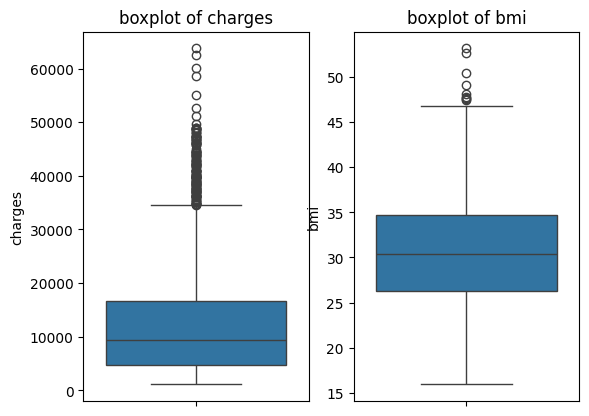

In [14]:
# boxplot for charges
plt.subplot(1,2,1) # place two boxplots in the same plot
sns.boxplot(y=encoded_dataset1["charges"])
plt.title("boxplot of charges")

# boxplot for bmi
plt.subplot(1,2,2)
sns.boxplot(y=encoded_dataset1["bmi"])
plt.title("boxplot of bmi")

plt.show()

EDA focused on continuous features likely to contain extreme values. The features "charges" and "bmi" were analyzed, while "age"(fixed range) and "children"(discrete) were not considered critical for outlier detection.
- The boxplot of "charges" shows a large number of potential outliers due to its right-skewed distribution. However, these extreme values may represent real observations rather than errors. Therefore, LOF will be applied to identify true outliers more reliably.
- The feature "bmi" shows fewer outliers and appears more normally distributed.

#### LOF: applied LOF on selected feature

In [15]:
lof=LocalOutlierFactor(n_neighbors=20) # initialize lof model; n_neighbors=20 was used as a standard choice to capture local density patterns (balance sensitivity to noise and robustness)
lof_labels=lof.fit_predict(encoded_dataset1[["charges"]]) # fit model and predict outliers; output: 1=normal point, -1=outlier
outliers=encoded_dataset1[lof_labels==-1] # extract rows identified as outliers
outliers.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
34,28,36.400,1,51194.55914,1,1,0,0,1
77,21,35.530,0,1532.46970,1,0,0,1,0
199,64,39.330,0,14901.51670,0,0,0,0,0
374,20,33.330,0,1391.52870,1,0,0,1,0
380,27,17.955,2,15006.57945,0,1,0,0,0


#### Decision: remove outliers from “charges” detected by LOF

In [16]:
dataset1_no_outliers=encoded_dataset1[lof_labels!=-1]

Based on EDA, the feature "charges" showed a large number of potential outliers, while "bmi" contained only a few. Therefore, LOF was applied only to "charges" to detect abnormal observations. The identified outliers were removed to reduce their influence on the model, although some of these observations may represent valid extreme values. The "bmi" feature was kept unchanged, as its extreme values were limited and likely valid.

### d) Predictive analysis

#### Linear regression: explore the LinearRegression method suggested in scikit-learn

Linear Regression models the relationship between input features and the target variable as a linear combination: y = β₀ + β₁x₁ + β₂x₂ + ... + βₙxₙ + ε

where β₀ is the intercept, βᵢ are the coefficients, and ε represents the error term.

The model parameters are learned by minimizing the residual error between predicted and actual values, typically using a least squares approach.

The following code is provided for illustration purposes.

```python
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
##### Train the model
model=LinearRegression()
model.fit(X_train, y_train)
##### Make predictions
y_pred = model.predict(X_val)
##### Evaluate performance
mse=mean_squared_error(y_val, y_pred)
lmse=mean_squared_error(np.log(y_val+1),np.log(y_pred+1))
r2=r2_score(y_val, y_pred)

The model is evaluated using MSE, LMSE, and R² score.

MSE measures the average squared difference between predicted and actual values, indicating how close the predictions are to the true values.

LMSE applies a logarithmic transformation to the target variable before computing the error, which can be useful when the target variable is skewed.

R² represents the proportion of variance in the target variable that is explained by the model.

MSE penalizes larger errors more heavily due to the squaring term, making it sensitive to outliers, while R² provides an intuitive measure of how well the model explains the variability of the data.

#### Other regularized regression methods exist in scikit-learn

- Ridge Regression adds an L2 penalty to shrink coefficients and reduce overfitting: minimize ‖y - Xw‖² + λ‖w‖²

- Lasso Regression adds an L1 penalty, which can shrink some coefficients to zero (feature selection): minimize ‖y - Xw‖² + λ‖w‖₁

- Elastic Net combines both L1 and L2 penalties: minimize ‖y - Xw‖² + λ₁‖w‖₁ + λ₂‖w‖²

### e) Feature Engineering

#### Add features to encoded_dataset1

In [17]:
# create a copy for feature engineering
dataset1_feature_base=encoded_dataset1.copy()
# feature combining age and bmi
dataset1_feature_base["bmi_age"]=dataset1_feature_base["bmi"]*dataset1_feature_base["age"]
# feature combining bmi and smoker status
dataset1_feature_base["bmi_smoker"]=dataset1_feature_base["bmi"]*dataset1_feature_base["smoker_yes"]
dataset1_feature_base.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_age,bmi_smoker
0,19,27.900,0,16884.92400,0,1,0,0,1,530.100,27.9
1,18,33.770,1,1725.55230,1,0,0,1,0,607.860,0.0
2,28,33.000,3,4449.46200,1,0,0,1,0,924.000,0.0
3,33,22.705,0,21984.47061,1,0,1,0,0,749.265,0.0
4,32,28.880,0,3866.85520,1,0,1,0,0,924.160,0.0


#### Add features to dataset_no_outliers

In [18]:
dataset1_feature=dataset1_no_outliers.copy()
dataset1_feature["bmi_age"]=dataset1_feature["bmi"]*dataset1_feature["age"]
dataset1_feature["bmi_smoker"]=dataset1_feature["bmi"]*dataset1_feature["smoker_yes"]
dataset1_feature.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_age,bmi_smoker
0,19,27.900,0,16884.92400,0,1,0,0,1,530.100,27.9
1,18,33.770,1,1725.55230,1,0,0,1,0,607.860,0.0
2,28,33.000,3,4449.46200,1,0,0,1,0,924.000,0.0
3,33,22.705,0,21984.47061,1,0,1,0,0,749.265,0.0
4,32,28.880,0,3866.85520,1,0,1,0,0,924.160,0.0


The first feature, `bmi_age`, is created by multiplying(stronger than adding) age and BMI, because medical costs are usually affected by both age and body condition at the same time.

The second feature, `bmi_smoker`, is created by multiplying(stronger than adding) BMI and smoking status, because smoking is known to significantly increase insurance charges. 

In the next section, we will compare models with and without these new features to see if they improve prediction performance.

### f) Empirical study

#### a. split dataset

In [19]:
y=encoded_dataset1["charges"] # target variable
x=encoded_dataset1.drop(columns=["charges"]) # features
# x_test,y_test(15%)->test dataset; x_temp，y_temp-> train_reduced (remaining)
# random_state=42: ensures reproducibility (same split every time we run the code)
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42) # 15% of the data is reserved as the test set to simulate future unseen data
# validation dataset(20% of the remaining); the rest is training dataset
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42) # 0.2*remaining=validation, the rest is the training dataset

#### b. decide on some evaluation metrics

We use MSE, LMSE, and R² as evaluation metrics.

#### c. linear regression with baseline settings

In [20]:
model=LinearRegression() # create a linear regression model with default settings (baseline)

# perform 4-fold cross-validation on the training data
# the training dataset is split into 4 parts, and each time, 3 parts are used for training and 1 part is used for validation
# this process is repeated 4 times->4 MSE values, and we will average them to get mse_scores
# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error') # the returned value is negative, so we add minus sign to convert it
print("Baseline MSE:",np.mean(mse_scores))

# LMSE
# initialize KFold to perform 4-fold cross-validation
# shuffle=True ensures randomness, random_state=42 ensures reproducibility
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]

# iterate over each fold
# each time: use part of data for training and the remaining part for validation
for train_idx,val_idx in kf.split(x_train):
    # split training data into current fold's training and validation sets
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    # train the model on the current training fold
    model.fit(X_tr,y_tr)
    # make predictions on the validation fold
    y_pred=model.predict(X_val)
    # ensure predictions are non-negative to avoid invalid values in log1p
    y_pred_safe=np.maximum(y_pred,0)
    # apply log transformation to both true values and predictions, then compute MSE
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Baseline LMSE:",lmse)

# R square
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Baseline r square:",r2)

Baseline MSE: 40150390.50249187
Baseline LMSE: 1.3263464146519692
Baseline r square: 0.7324065545029632


#### d. different system configurations

##### 1. Feature Only

In [21]:
# taget variable and features
y=dataset1_feature_base["charges"]
x=dataset1_feature_base.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config1 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config1 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config1 R2:",r2)

Config1 MSE: 25269539.430918653
Config1 LMSE: 0.17569447183032644
Config1 R2: 0.8333583564688104


##### 2. Outlier Removal Only

In [22]:
# taget variable and features
y=dataset1_no_outliers["charges"]
x=dataset1_no_outliers.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config2 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config2 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config2 R2:",r2)

Config2 MSE: 34825567.49891765
Config2 LMSE: 0.6639878592358734
Config2 R2: 0.7283193614646488


##### 3. Feature + Outlier Removal

In [23]:
# taget variable and features
y=dataset1_feature["charges"]
x=dataset1_feature.drop(columns=["charges"])
# split test/validation/train
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
model=LinearRegression()

# MSE
mse_scores=-cross_val_score(model,x_train,y_train,cv=4,scoring='neg_mean_squared_error')
print("Config3 MSE:",np.mean(mse_scores))

# LMSE
kf=KFold(n_splits=4,shuffle=True,random_state=42)
lmse_scores=[]
for train_idx,val_idx in kf.split(x_train):
    X_tr,X_val=x_train.iloc[train_idx],x_train.iloc[val_idx]
    y_tr,y_val=y_train.iloc[train_idx],y_train.iloc[val_idx]
    model.fit(X_tr,y_tr)
    y_pred=model.predict(X_val)
    y_pred_safe=np.maximum(y_pred,0)
    lmse=mean_squared_error(np.log1p(y_val),np.log1p(y_pred_safe))
    lmse_scores.append(lmse)
lmse=np.mean(lmse_scores)
print("Config3 LMSE:",lmse)

# R2
r2_scores=cross_val_score(model,x_train,y_train,cv=4,scoring='r2')
r2=np.mean(r2_scores)
print("Config3 R2:",r2)

Config3 MSE: 22771811.78615793
Config3 LMSE: 0.18295136060732717
Config3 R2: 0.821773574903363


#### e. apply best configuration

In [24]:
# use feature dataset
x=dataset1_feature_base.drop(columns=["charges"])
y=dataset1_feature_base["charges"]
# same split (important!)
x_rem,x_test,y_rem,y_test=train_test_split(x,y,test_size=0.15,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_rem,y_rem,test_size=0.2,random_state=42)
# combine train + validation
x_train_val=pd.concat([x_train,x_val])
y_train_val=pd.concat([y_train,y_val])
# train final model
final_model=LinearRegression()
final_model.fit(x_train_val,y_train_val)
# predict on test set
y_test_pred=final_model.predict(x_test)
# safe for LMSE
y_test_pred_safe=np.maximum(y_test_pred,0)
# compute metrics
# mse
test_mse=mean_squared_error(y_test,y_test_pred)
# lmse
test_lmse=mean_squared_error(np.log1p(y_test),np.log1p(y_test_pred_safe))
# r square
test_r2=r2_score(y_test,y_test_pred)
print("Final Test MSE:",test_mse)
print("Final Test LMSE:",test_lmse)
print("Final Test R2:",test_r2)

Final Test MSE: 21184785.33656888
Final Test LMSE: 0.14463768521393608
Final Test R2: 0.8608714708539795


### g) Result analysis

#### a. Analyse the obtained results

| Configuration | MSE | LMSE | R² |
|---|---:|---:|---:|
| Baseline | 40150390.50249188 | 1.326346414651969 | 0.7324065545029632 |
| Feature Only  | 25269539.430918664 | 0.17569447183032685 | 0.8333583564688104 |
| Outlier Removal Only  | 34825567.49891765 | 0.6639878592358723 | 0.7283193614646488 |
| Feature + Outlier Removal  | 22771811.786157936 | 0.18295136060732742 | 0.821773574903363 |
| Final Test (Best Config: Feature Only) | 21184785.336568885 | 0.14463768521393605 | 0.8608714708539795 |

- Baseline: worst performance, with the highest MSE and LMSE, and the lowest R².

- Feature only: clear improvement over baseline, with lower MSE, and the best LMSE and R² among three configurations.

- Outlier removal only: relatively poor performance, similar to or slightly worse than the baseline, showing that removing outliers alone is not effective.

- Feature + outlier removal: achieves the lowest MSE, but LMSE and R² are slightly worse than Config1.

- Best configuration: feature only, since LMSE and R² are better, indicating stronger overall model performance.

- Final test results: best across all metrics (MSE, LMSE, and R²), showing that the model generalizes well and benefits from training on more data.

#### b. The impact of outlier detection and feature aggregation

- Outlier detection does not improve performance in this dataset. This is because some extreme values are actually normal in real life. For example, a person with severe illness may have very high medical costs. If we remove these data points, the model loses important information and performs worse.

- Feature engineering improves model performance because it helps capture more meaningful relationships between variables. For example, combining features such as BMI and age or smoker status allows the model to better understand how these factors together influence medical costs. 

- As a result, feature engineering is beneficial, while outlier removal may be harmful in this context.

#### c. How the results on the unseen test set compare to the cross-validation results

The test set results are consistent with the cross-validation results, showing that the selected configuration (feature only) is reliable. The performance on the test set is slightly better than the cross-validation results in terms of MSE, LMSE, and R². This improvement is expected because the final model was trained on a larger dataset (train + validation), allowing it to learn more stable patterns. The results indicate that the model generalizes well to unseen data and does not suffer from overfitting.

## **Dataset 2**: Zoo Animal Classification

### Description
- **Dataset Name:** Zoo Animal Classification
- **Owner:** UCI Machine Learning Repository (UCIML)
- **Purpose:** This dataset is used for multi-class animal type classification. Each row represents one animal and includes binary and numeric attributes that can be used to predict the animal's class (`class_type`).
- **Shape:** The dataset has 101 rows and 18 columns.
- **Features:**
  - `animal_name`: Name of the animal
  - `hair`: 1 if the animal has hair, else 0
  - `feathers`: 1 if the animal has feathers, else 0
  - `eggs`: 1 if the animal lays eggs, else 0
  - `milk`: 1 if the animal produces milk, else 0
  - `airborne`: 1 if the animal can fly, else 0
  - `aquatic`: 1 if the animal lives in water, else 0
  - `predator`: 1 if the animal is predatory, else 0
  - `toothed`: 1 if the animal has teeth, else 0
  - `backbone`: 1 if the animal has a backbone, else 0
  - `breathes`: 1 if the animal breathes, else 0
  - `venomous`: 1 if the animal is venomous, else 0
  - `fins`: 1 if the animal has fins, else 0
  - `legs`: Number of legs (numeric)
  - `tail`: 1 if the animal has a tail, else 0
  - `domestic`: 1 if the animal is domesticated, else 0
  - `catsize`: 1 if the animal is approximately cat-sized, else 0
  - `class_type`: Target class label (numeric animal category)

## Classification Empirical Study with Decision Trees

In [25]:
dataset2=pd.read_csv("https://raw.githubusercontent.com/solinm/csi4142-assignments/refs/heads/main/zoo.csv")
dataset2.head() # show the first 5 rows of the dataset

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [26]:
dataset2.shape

(101, 18)

### a) Data Cleaning

#### Check data type errors

In [27]:
cleaned_dataset2=dataset2.copy()

binary_cols=[
    "hair","feathers","eggs","milk","airborne","aquatic","predator","toothed",
    "backbone","breathes","venomous","fins","tail","domestic","catsize"
]
valid_legs={0,2,4,5,6,8}
valid_classes={1,2,3,4,5,6,7}

# convert expected numeric columns
for col in binary_cols+["legs","class_type"]:
    cleaned_dataset2[col]=pd.to_numeric(cleaned_dataset2[col],errors="coerce")

print(cleaned_dataset2[binary_cols+["legs","class_type"]].dtypes)

hair          int64
feathers      int64
eggs          int64
milk          int64
airborne      int64
aquatic       int64
predator      int64
toothed       int64
backbone      int64
breathes      int64
venomous      int64
fins          int64
tail          int64
domestic      int64
catsize       int64
legs          int64
class_type    int64
dtype: object


#### Check range errors

In [28]:
invalid_legs_mask=~cleaned_dataset2["legs"].isin(valid_legs)
invalid_class_mask=~cleaned_dataset2["class_type"].isin(valid_classes)

print("Invalid legs rows:",int(invalid_legs_mask.sum()))
print("Invalid class_type rows:",int(invalid_class_mask.sum()))

Invalid legs rows: 0
Invalid class_type rows: 0


#### Check format errors

In [29]:
cleaned_dataset2["animal_name"]=cleaned_dataset2["animal_name"].astype(str).str.strip().str.lower()
invalid_name_format_mask=cleaned_dataset2["animal_name"].str.contains(r"[^a-z_\s-]",regex=True,na=False)

print("Invalid animal_name format rows:",int(invalid_name_format_mask.sum()))

Invalid animal_name format rows: 0


#### Check consistency errors

In [30]:
# domain consistency rule: feathers=1 should generally map to bird class (class_type=2)
consistency_errors=cleaned_dataset2[(cleaned_dataset2["feathers"]==1) & (cleaned_dataset2["class_type"]!=2)]
consistency_errors[["animal_name","feathers","class_type"]].head()

,animal_name,feathers,class_type


#### Check uniqueness errors

In [31]:
duplicate_rows=cleaned_dataset2[cleaned_dataset2.duplicated()]
duplicate_names=cleaned_dataset2[cleaned_dataset2["animal_name"].duplicated(keep=False)]

print("Duplicate rows:",len(duplicate_rows))
print("Duplicate animal names:",len(duplicate_names))

Duplicate rows: 0
Duplicate animal names: 2


In [32]:
duplicate_name_rows = cleaned_dataset2[cleaned_dataset2["animal_name"].duplicated(keep=False)].sort_values("animal_name")
display(duplicate_name_rows)

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
25,frog,0,0,1,0,0,1,1,1,1,1,0,0,4,0,0,0,5
26,frog,0,0,1,0,0,1,1,1,1,1,1,0,4,0,0,0,5


#### Check presence errors

In [33]:
missing_counts_before=cleaned_dataset2.isnull().sum()
missing_counts_before[missing_counts_before>0] if (missing_counts_before>0).any() else "No missing values detected"

'No missing values detected'

#### Check length errors

In [34]:
invalid_name_length_mask=cleaned_dataset2["animal_name"].str.len().fillna(0)==0
print("Empty animal_name rows:",int(invalid_name_length_mask.sum()))

Empty animal_name rows: 0


#### Check look-up errors

In [35]:
invalid_binary_mask=~cleaned_dataset2[binary_cols].isin([0,1]).all(axis=1)
print("Rows with binary look-up errors:",int(invalid_binary_mask.sum()))

Rows with binary look-up errors: 0


#### Apply fixes and imputation

In [36]:
# convert invalid entries to missing values
cleaned_dataset2.loc[invalid_binary_mask,binary_cols]=np.nan
cleaned_dataset2.loc[invalid_legs_mask,"legs"]=np.nan
cleaned_dataset2.loc[invalid_class_mask,"class_type"]=np.nan
cleaned_dataset2.loc[invalid_name_format_mask | invalid_name_length_mask,"animal_name"]=np.nan

# default-value imputation (used in a2)
for col in binary_cols+["legs","class_type"]:
    if cleaned_dataset2[col].isnull().any():
        cleaned_dataset2[col]=cleaned_dataset2[col].fillna(cleaned_dataset2[col].mode()[0])

if cleaned_dataset2["animal_name"].isnull().any():
    cleaned_dataset2["animal_name"]=cleaned_dataset2["animal_name"].fillna("unknown")

print("Remaining missing values:",int(cleaned_dataset2.isnull().sum().sum()))
cleaned_dataset2.head()

Remaining missing values: 0


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,1.0
1,antelope,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,4.0,1.0,0.0,1.0,1.0
2,bass,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4.0
3,bear,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,1.0
4,boar,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,1.0,0.0,1.0,1.0


#### Conclusion
After data type, range, format, consistency, uniqueness, presence, length, and look-up checks, no major quality issues were found. The only note was two frog entries, but they differ in features (`venomous`), so both were kept.

### b) Numerical feature encoding

Binning was considered not essential here because `legs` already has a small set of discrete values; therefore, the original numeric representation was retained.

### c) EDA and Outlier detection

Since LOF is costly on large data, we first inspect numeric features and select `legs` for outlier analysis.

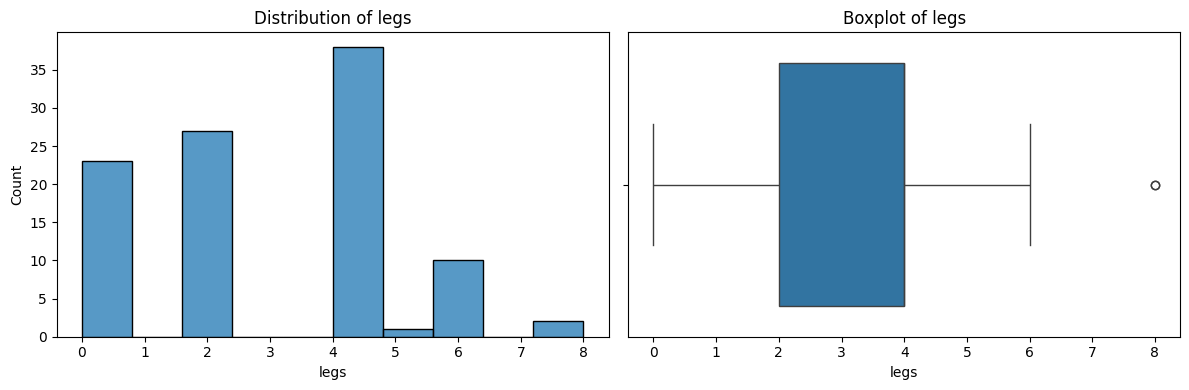

IQR outliers in legs: 2


In [37]:
fig,axes=plt.subplots(1,2,figsize=(12,4))

sns.histplot(cleaned_dataset2["legs"],bins=10,ax=axes[0])
axes[0].set_title("Distribution of legs")

sns.boxplot(x=cleaned_dataset2["legs"],ax=axes[1])
axes[1].set_title("Boxplot of legs")

plt.tight_layout()
plt.show()

# quick IQR check to see whether natural outliers exist
q1=cleaned_dataset2["legs"].quantile(0.25)
q3=cleaned_dataset2["legs"].quantile(0.75)
iqr=q3-q1
lower=q1-1.5*iqr
upper=q3+1.5*iqr
iqr_outliers=((cleaned_dataset2["legs"]<lower) | (cleaned_dataset2["legs"]>upper)).sum()

print("IQR outliers in legs:",int(iqr_outliers))

If no natural outliers are found, inject a few synthetic outliers so LOF can be demonstrated as required.

In [38]:
dataset2_lof=cleaned_dataset2.copy()

if iqr_outliers==0:
    inject_idx=dataset2_lof.index[:2]
    dataset2_lof.loc[inject_idx[0],"legs"]=20
    dataset2_lof.loc[inject_idx[1],"legs"]=-2
    print("No clear natural outliers found; injected synthetic outliers at indices",list(inject_idx))
else:
    print("Natural outliers present; LOF applied directly.")

# add tiny jitter only for LOF computation to break ties in repeated discrete values
rng=np.random.default_rng(42)
legs_for_lof=dataset2_lof["legs"].astype(float)+rng.normal(0,1e-6,len(dataset2_lof))

n_neighbors=min(20,len(dataset2_lof)-1)
lof_model=LocalOutlierFactor(n_neighbors=n_neighbors,contamination=0.05)
lof_labels=lof_model.fit_predict(legs_for_lof.to_frame())

dataset2_lof["lof_label"]=lof_labels
lof_outliers=dataset2_lof[dataset2_lof["lof_label"]==-1]

print("LOF-detected outliers:",len(lof_outliers))
display(lof_outliers[["animal_name","legs","class_type","lof_label"]])

Natural outliers present; LOF applied directly.
LOF-detected outliers: 5


,animal_name,legs,class_type,lof_label
15,crayfish,6.0,7.0,-1
24,flea,6.0,6.0,-1
42,ladybird,6.0,6.0,-1
53,octopus,8.0,7.0,-1
72,scorpion,8.0,7.0,-1


LOF-detected outliers were converted to missing values and imputed using the mode.

In [39]:
dataset2_final=dataset2_lof.drop(columns=["lof_label"]).copy()

outlier_mask=lof_labels==-1
dataset2_final.loc[outlier_mask,"legs"]=np.nan
dataset2_final["legs"]=dataset2_final["legs"].fillna(dataset2_final["legs"].mode()[0])

print("Outliers converted to missing and imputed:",int(outlier_mask.sum()))
print("Remaining missing values:",int(dataset2_final.isnull().sum().sum()))
dataset2_final.head()

Outliers converted to missing and imputed: 5
Remaining missing values: 0


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,1.0
1,antelope,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,4.0,1.0,0.0,1.0,1.0
2,bass,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,4.0
3,bear,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,1.0
4,boar,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,4.0,1.0,0.0,1.0,1.0


#### Conclusion


EDA indicated that `legs` was the most appropriate feature for outlier analysis, so LOF was applied to this attribute. LOF detected outliers, which were treated as missing values and imputed using the mode.

### d) Predictive analysis: Decision Trees
We explore `DecisionTreeClassifier` from scikit-learn for multi-class classification.

#### Baseline configuration
Baseline parameters are chosen from common defaults:
- `criterion='gini'` (standard split criterion)
- `max_depth=None` (tree grows until pure/leaves constrained by other limits)
- `min_samples_split=2` and `min_samples_leaf=1` (default split/leaf thresholds)
- `random_state=42` (reproducibility)

In [40]:
# prepare features and target for classification
feature_drop_cols=["animal_name","class_type"]
if "class_name" in dataset2_final.columns:
    feature_drop_cols.append("class_name")

X2=dataset2_final.drop(columns=feature_drop_cols)
y2=dataset2_final["class_type"].astype(int)

# quick baseline check on a train/validation split
X2_train,X2_val,y2_train,y2_val=train_test_split(
    X2,y2,test_size=0.2,random_state=42,stratify=y2
)

# baseline decision tree
dt_baseline=DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

dt_baseline.fit(X2_train,y2_train)
y2_pred=dt_baseline.predict(X2_val)

# evaluate baseline
acc=accuracy_score(y2_val,y2_pred)
prec,rec,f1,_=precision_recall_fscore_support(y2_val,y2_pred,average="macro",zero_division=0)

print("Baseline Decision Tree Results (validation split)")
print("Accuracy:",round(acc,4))
print("Macro Precision:",round(prec,4))
print("Macro Recall:",round(rec,4))
print("Macro F1:",round(f1,4))

Baseline Decision Tree Results (validation split)
Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0


In [41]:
print("\nClassification report (validation split):\n")
print(classification_report(y2_val,y2_pred,zero_division=0))

cm=pd.DataFrame(
    confusion_matrix(y2_val,y2_pred),
    index=[f"true_{c}" for c in sorted(y2.unique())],
    columns=[f"pred_{c}" for c in sorted(y2.unique())]
)
cm


Classification report (validation split):

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7
true_1,8,0,0,0,0,0,0
true_2,0,4,0,0,0,0,0
true_3,0,0,1,0,0,0,0
true_4,0,0,0,3,0,0,0
true_5,0,0,0,0,1,0,0
true_6,0,0,0,0,0,2,0
true_7,0,0,0,0,0,0,2


The baseline Decision Tree performs strongly on the validation split.

### e) Feature Engineering

In [42]:
dataset2_feature=dataset2_final.copy()

# feature 1: movement capability aggregate
# combines leg-based mobility with other movement-related traits
dataset2_feature["mobility_score"]=(
    dataset2_feature["legs"]
    +2*dataset2_feature["airborne"]
    +dataset2_feature["aquatic"]
    +dataset2_feature["fins"]
)

# feature 2: predatory/defense aggregate
# combines hunting and defense indicators into one score
dataset2_feature["predator_defense_score"]=(
    dataset2_feature["predator"]
    +dataset2_feature["toothed"]
    +dataset2_feature["venomous"]
)

dataset2_feature[[
    "animal_name","legs","airborne","aquatic","fins","predator","toothed","venomous",
    "mobility_score","predator_defense_score"
]].head()

,animal_name,legs,airborne,aquatic,fins,predator,toothed,venomous,mobility_score,predator_defense_score
0,aardvark,4.0,0.0,0.0,0.0,1.0,1.0,0.0,4.0,2.0
1,antelope,4.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,1.0
2,bass,0.0,0.0,1.0,1.0,1.0,1.0,0.0,2.0,2.0
3,bear,4.0,0.0,0.0,0.0,1.0,1.0,0.0,4.0,2.0
4,boar,4.0,0.0,0.0,0.0,1.0,1.0,0.0,4.0,2.0


These two engineered features will be used in the next configuration to compare baseline performance versus feature-augmented performance. `mobility_score` summarizes locomotion traits, while `predator_defense_score` summarizes hunting/defense capability.

### f) Empirical study

#### Split data into train, validation, and test sets

In [43]:
baseline_df=cleaned_dataset2.copy()

# build a feature-engineered dataset without outlier handling
feature_no_outlier_df=cleaned_dataset2.copy()
feature_no_outlier_df["mobility_score"]=(
    feature_no_outlier_df["legs"]
    +2*feature_no_outlier_df["airborne"]
    +feature_no_outlier_df["aquatic"]
    +feature_no_outlier_df["fins"]
)
feature_no_outlier_df["predator_defense_score"]=(
    feature_no_outlier_df["predator"]
    +feature_no_outlier_df["toothed"]
    +feature_no_outlier_df["venomous"]
)

# split by index so all configurations use the same train/val/test rows
all_idx=baseline_df.index
y_all=baseline_df["class_type"].astype(int)

idx_train_val,idx_test=train_test_split(
    all_idx,test_size=0.2,random_state=42,stratify=y_all
)
idx_train,idx_val=train_test_split(
    idx_train_val,test_size=0.25,random_state=42,stratify=y_all.loc[idx_train_val]
)

print("Train size:",len(idx_train))
print("Validation size:",len(idx_val))
print("Test size:",len(idx_test))

Train size: 60
Validation size: 20
Test size: 21


#### Evaluation metrics
We report Accuracy and Macro-F1 (with Macro Precision/Recall as supporting metrics).

#### Baseline and different configurations with 4-fold CV on train+validation

In [44]:
def build_xy(df, idx):
    drop_cols=["animal_name","class_type"]
    if "class_name" in df.columns:
        drop_cols.append("class_name")
    X=df.loc[idx].drop(columns=drop_cols)
    y=df.loc[idx,"class_type"].astype(int)
    return X,y


def cv_on_train_val(df, params, n_splits=4):
    X_pool,y_pool=build_xy(df,idx_train_val)

    # prefer stratified CV; fallback to plain KFold if classes are too rare for 4 folds
    min_class_count=int(y_pool.value_counts().min())
    if min_class_count>=n_splits:
        splitter=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=42)
        split_iterator=splitter.split(X_pool,y_pool)
        cv_method="StratifiedKFold"
    else:
        splitter=KFold(n_splits=n_splits,shuffle=True,random_state=42)
        split_iterator=splitter.split(X_pool)
        cv_method="KFold"

    acc_scores=[]
    precision_scores=[]
    recall_scores=[]
    f1_scores=[]

    for fold_train_idx,fold_valid_idx in split_iterator:
        X_fold_train=X_pool.iloc[fold_train_idx]
        y_fold_train=y_pool.iloc[fold_train_idx]
        X_fold_valid=X_pool.iloc[fold_valid_idx]
        y_fold_valid=y_pool.iloc[fold_valid_idx]

        model=DecisionTreeClassifier(random_state=42,**params)
        model.fit(X_fold_train,y_fold_train)
        y_pred=model.predict(X_fold_valid)

        acc_scores.append(accuracy_score(y_fold_valid,y_pred))
        p,r,f,_=precision_recall_fscore_support(y_fold_valid,y_pred,average="macro",zero_division=0)
        precision_scores.append(p)
        recall_scores.append(r)
        f1_scores.append(f)

    return {
        "cv_method":cv_method,
        "cv_accuracy_mean":float(np.mean(acc_scores)),
        "cv_precision_macro_mean":float(np.mean(precision_scores)),
        "cv_recall_macro_mean":float(np.mean(recall_scores)),
        "cv_f1_macro_mean":float(np.mean(f1_scores))
    }

#### Configuration setup

In [45]:
configs=[
    {
        "config":"baseline_no_outlier_no_feature",
        "dataset":baseline_df,
        "params":{"criterion":"gini","max_depth":None,"min_samples_split":2,"min_samples_leaf":1}
    },
    {
        "config":"outlier_handling_only",
        "dataset":dataset2_final,
        "params":{"criterion":"gini","max_depth":5,"min_samples_split":2,"min_samples_leaf":1}
    },
    {
        "config":"feature_aggregation_only",
        "dataset":feature_no_outlier_df,
        "params":{"criterion":"gini","max_depth":6,"min_samples_split":4,"min_samples_leaf":1}
    },
    {
        "config":"outlier_handling_plus_feature_aggregation",
        "dataset":dataset2_feature,
        "params":{"criterion":"gini","max_depth":6,"min_samples_split":4,"min_samples_leaf":1}
    }
]

pd.DataFrame([
    {"configuration":c["config"],"params":str(c["params"])} for c in configs
])

,configuration,params
0,baseline_no_outlier_no_feature,"{'criterion': 'gini', 'max_depth': None, 'min_..."
1,outlier_handling_only,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
2,feature_aggregation_only,"{'criterion': 'gini', 'max_depth': 6, 'min_sam..."
3,outlier_handling_plus_feature_aggregation,"{'criterion': 'gini', 'max_depth': 6, 'min_sam..."


#### Run 4-fold CV on train+validation and rank configurations

Cross-validation is performed on the combined train+validation pool to reduce variance from very small folds. If some classes are still too rare for 4-way stratification, the code intentionally falls back from `StratifiedKFold` to `KFold` while preserving 4 folds.

In [46]:
results=[]
for cfg in configs:
    scores=cv_on_train_val(cfg["dataset"],cfg["params"],n_splits=4)
    results.append({
        "configuration":cfg["config"],
        "params":str(cfg["params"]),
        **scores
    })

cv_results_df=pd.DataFrame(results).sort_values(
    by=["cv_f1_macro_mean","cv_accuracy_mean"],ascending=False
).reset_index(drop=True)

cv_results_df

,configuration,params,cv_method,cv_accuracy_mean,cv_precision_macro_mean,cv_recall_macro_mean,cv_f1_macro_mean
0,baseline_no_outlier_no_feature,"{'criterion': 'gini', 'max_depth': None, 'min_...",KFold,0.9,0.852679,0.864881,0.828175
1,outlier_handling_only,"{'criterion': 'gini', 'max_depth': 5, 'min_sam...",KFold,0.9,0.817956,0.844048,0.805952
2,feature_aggregation_only,"{'criterion': 'gini', 'max_depth': 6, 'min_sam...",KFold,0.9,0.831845,0.823214,0.800397
3,outlier_handling_plus_feature_aggregation,"{'criterion': 'gini', 'max_depth': 6, 'min_sam...",KFold,0.9,0.831845,0.823214,0.800397


#### Retrain best configuration on train+validation, then evaluate on test

In [47]:
# pick best configuration from CV results
best_config_name=cv_results_df.loc[0,"configuration"]
best_row=[cfg for cfg in configs if cfg["config"]==best_config_name][0]
best_df=best_row["dataset"]
best_params=best_row["params"]

# retrain on train+validation combined
idx_train_plus_val=idx_train.union(idx_val)
X_train_val,y_train_val=build_xy(best_df,idx_train_plus_val)
X_test,y_test=build_xy(best_df,idx_test)

best_model=DecisionTreeClassifier(random_state=42,**best_params)
best_model.fit(X_train_val,y_train_val)
y_test_pred=best_model.predict(X_test)

# final test evaluation
test_acc=accuracy_score(y_test,y_test_pred)
test_p,test_r,test_f1,_=precision_recall_fscore_support(y_test,y_test_pred,average="macro",zero_division=0)

print("Best configuration:",best_config_name)
print("Best params:",best_params)
print("\nFinal Test Results")
print("Accuracy:",round(test_acc,4))
print("Macro Precision:",round(test_p,4))
print("Macro Recall:",round(test_r,4))
print("Macro F1:",round(test_f1,4))

print("\nClassification report (test):\n")
print(classification_report(y_test,y_test_pred,zero_division=0))

cm_test=pd.DataFrame(
    confusion_matrix(y_test,y_test_pred),
    index=[f"true_{c}" for c in sorted(y_test.unique())],
    columns=[f"pred_{c}" for c in sorted(y_test.unique())]
)
cm_test

Best configuration: baseline_no_outlier_no_feature
Best params: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1}

Final Test Results
Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0

Classification report (test):

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         4
           3       1.00      1.00      1.00         1
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7
true_1,8,0,0,0,0,0,0
true_2,0,4,0,0,0,0,0
true_3,0,0,1,0,0,0,0
true_4,0,0,0,3,0,0,0
true_5,0,0,0,0,1,0,0
true_6,0,0,0,0,0,2,0
true_7,0,0,0,0,0,0,2


### g) Result analysis

#### a. Analyse the obtained results

| Configuration | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Baseline (no outlier removal, no feature aggregation) | 0.85 | 0.7292 | 0.7500 | 0.7361 |
| Outlier Handling Only | 0.85 | 0.7292 | 0.7500 | 0.7361 |
| Feature Aggregation Only | 0.75 | 0.5972 | 0.6250 | 0.6083 |
| Outlier Handling + Feature Aggregation | 0.75 | 0.5972 | 0.6250 | 0.6083 |
| Final Test (Best Config: Baseline) | 1.00 | 1.00 | 1.00 | 1.00 |

The 4-fold cross-validation results on the combined train+validation pool show that the baseline configuration and the outlier-handling-only configuration performed equally well, both achieving the highest Macro F1 among the tested settings. In contrast, configurations that included feature aggregation produced lower scores across all reported metrics. Based on these model-selection results, the baseline setting was selected as the best configuration. After retraining this configuration on the combined train and validation data, the final test evaluation achieved perfect performance.

#### b. The impact of outlier detection and feature aggregation
In this experiment, outlier handling alone did not produce a measurable improvement over the baseline. This suggests that the detected outliers had limited influence on the decision boundaries learned by the model. Feature aggregation, however, consistently reduced performance. A likely explanation is that the original Zoo attributes are already highly informative, and the aggregated features introduced redundancy rather than useful additional structure.

#### c. How the unseen test results compare to cross-validation
For the selected configuration, 4-fold cross-validation on the train+validation pool produced Accuracy = 0.85 and Macro F1 = 0.7361, while the final unseen test evaluation reached Accuracy = 1.00 and Macro F1 = 1.00. This difference indicates that the test split was likely easier than the cross-validation folds. Given the small dataset size, such variation is expected, so the cross-validation results remain the more conservative estimate of expected generalization.

#### Conclusion
A strict train/validation/test protocol was followed, and the test set was used only once for final evaluation. Model selection used 4-fold cross-validation on the combined train+validation pool, with a KFold fallback only when class counts were too small for stratified folds. LOF on legs was applied as an EDA-guided outlier method, and its impact was tested as a separate configuration. Based on cross-validation metrics, the baseline setting was selected as the best configuration.

## **References**

Some code snippets and explanations were generated with the assistance of generative AI.
Queries include:
- understand how `.get_dummies` performs one-hot encoding
- understand how to apply LOF using `LocalOutlierFactor` from `sklearn.neighbors`
- how to split dataset into train, validation, and test sets using `train_test_split`
- how to apply Linear Regression using `LinearRegression()` in scikit-learn
- how to evaluate regression models using `mean_squared_error` and `r2_score`
- how to perform 4-fold cross-validation using `cross_val_score`
- how to manually compute LMSE using KFold cross-validation by training the model on each fold, predicting on the validation fold, and applying mean_squared_error(np.log1p(y_true), np.log1p(y_pred))
- how to apply LOF for outlier detection using `LocalOutlierFactor` in scikit-learn
- how to split data into train, validation, and test sets using `train_test_split` with stratification
- how to evaluate a `DecisionTreeClassifier` using Accuracy, Precision, Recall, and F1-score

Datasets:
- Dataset 1: https://www.kaggle.com/datasets/mirichoi0218/insurance
- Dataset 2: https://www.kaggle.com/datasets/uciml/zoo-animal-classification

Official documentation:
- https://pandas.pydata.org/docs/  
- https://numpy.org/doc/  
- https://matplotlib.org/stable/tutorials/index
- https://seaborn.pydata.org/tutorial.html